# Aprendizaje supervisado
## Detección de Falsas Alarmas en el C5

**Formulación del problema**

Cada vez que entra un reporte al C5, el sistema debe decidir si despachará una unidad de inmediato o primero activará las cámaras de vigilancia para verificar el incidente.

El objetivo de este notebook es construir un modelo que, con la información disponible *en el momento del reporte*, identifique qué llamadas tienen mayor riesgo de ser falsas alarmas para priorizar esa doble verificación.


**Instrucciones generales**

- Corre cada celda en orden
- Lee los comentarios y las celdas de texto
- Las celdas marcadas con `# PREGUNTA:` requieren que completes algo
- Las preguntas de la evaluación final estarán basadas en la práctica y análisis de este notebook


## 0. Librerías

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_curve, roc_auc_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', palette='crest')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

> **PREGUNTA:**
> ¿Cuáles son los algoritmos que se están cargando en la importación de paqueterías?

*Escribe tu respuesta aquí:*

---
## 1. Carga y limpieza de la base de datos

In [21]:
df = pd.read_csv('https://raw.githubusercontent.com/ElenaVillano/databases/refs/heads/main/db_falsas_alarmas.csv')

# Convertimos las columnas de fecha a tipo datetime
df['fecha_hora_creacion'] = pd.to_datetime(df['fecha_hora_creacion'])
df['fecha_hora_cierre']   = pd.to_datetime(df['fecha_hora_cierre'])

print(f'Registros totales: {len(df):,}')
print(f'Columnas: {df.columns.tolist()}')
df.head()

Registros totales: 124,261
Columnas: ['folio', 'fecha_hora_creacion', 'fecha_hora_cierre', 'tipo_incidente_c4', 'incidente_c4', 'alcaldia_inicio', 'codigo_cierre', 'clas_con_f_alarma', 'tipo_entrada', 'alcaldia_cierre', 'alcaldia_catalogo', 'colonia_catalogo', 'longitud', 'latitud']


,folio,fecha_hora_creacion,fecha_hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud
0,C5/20220923/04016,2022-09-23 18:38:34,2022-09-23 22:22:27,Accidente,Choque sin lesionados,VENUSTIANO CARRANZA,A,EMERGENCIA,LLAMADA DEL 911,VENUSTIANO CARRANZA,Venustiano Carranza,20 De Noviembre,-99.108352,19.443920
1,C5/20220829/00630,2022-08-29 02:56:31,2022-08-29 06:04:53,Accidente,Motociclista,CUAUHTEMOC,A,URGENCIAS MEDICAS,LLAMADA DEL 911,CUAUHTEMOC,Cuauhtémoc,Obrera,-99.140843,19.416669
2,C5/20220724/01907,2022-07-24 04:29:09,2022-07-24 07:36:49,Accidente,Choque sin lesionados,IZTAPALAPA,A,EMERGENCIA,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,San Andres Tetepilco,-99.130702,19.371340
3,C5/20240215/03071,2024-02-15 16:20:03,2024-02-15 20:52:19,Accidente,Choque sin lesionados,LA MAGDALENA CONTRERAS,A,EMERGENCIA,LLAMADA DEL 911,LA MAGDALENA CONTRERAS,La Magdalena Contreras,La Cruz,-99.233973,19.305985
4,C5/20221006/03493,2022-10-06 19:33:05,2022-10-06 22:37:08,Accidente,Choque sin lesionados,IZTAPALAPA,F,EMERGENCIA,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,Santa Martha Acatitla Norte,-99.013140,19.374476


### 1.1 Revisión de valores faltantes

In [22]:
print('Valores faltantes por columna:')
print(df.isnull().sum())

Valores faltantes por columna:
folio                     0
fecha_hora_creacion       0
fecha_hora_cierre         0
tipo_incidente_c4         0
incidente_c4              0
alcaldia_inicio           8
codigo_cierre             0
clas_con_f_alarma         0
tipo_entrada              0
alcaldia_cierre           8
alcaldia_catalogo       130
colonia_catalogo       2718
longitud                  0
latitud                   0
dtype: int64


Las columnas `alcaldia_inicio` y `colonia_catalogo` tienen algunos valores faltantes. Para propósitos y facilidad del ejercicio, quitaremos los valores nulos de la base.

> **PREGUNTA:**
> ¿A qué crees que se deban estos valores faltantes? ¿Existe información adicional para imputarlos?

*Escribe tu respuesta aquí:*



In [23]:
df = df.dropna(subset=['alcaldia_inicio','colonia_catalogo'])
print(f'Registros después de limpiar nulos: {len(df):,}')

Registros después de limpiar nulos: 121,540


In [24]:
print('Valores faltantes por columna:')
print(df.isnull().sum())

Valores faltantes por columna:
folio                   0
fecha_hora_creacion     0
fecha_hora_cierre       0
tipo_incidente_c4       0
incidente_c4            0
alcaldia_inicio         0
codigo_cierre           0
clas_con_f_alarma       0
tipo_entrada            0
alcaldia_cierre         0
alcaldia_catalogo      60
colonia_catalogo        0
longitud                0
latitud                 0
dtype: int64


### 1.2 ¿Qué significa cada código de cierre?

La columna `codigo_cierre` tiene 4 valores posibles:

| Código | Significado |
|--------|-------------|
| `A` | Atendido: emergencia real, se despachó una unidad |
| `F` | Falsa alarma: el incidente no existía o no requirió atención |
| `D` | Duplicado: alguien más ya reportó el mismo incidente |
| `I` | Informativo |

**Decisión analítica:** Los registros duplicados (`D`) representan múltiples personas reportando el *mismo* incidente real. Los tratamos como emergencias reales (`0`), no como falsas alarmas.

In [25]:
print('Distribución de codigo_cierre:')
print(df['codigo_cierre'].value_counts())
print()
print(f'Porcentaje de cada código:')
print(df['codigo_cierre'].value_counts(normalize=True).map('{:.1%}'.format))

Distribución de codigo_cierre:
codigo_cierre
D    51746
A    44404
F    24582
I      808
Name: count, dtype: int64

Porcentaje de cada código:
codigo_cierre
D    42.6%
A    36.5%
F    20.2%
I     0.7%
Name: proportion, dtype: str


> **PREGUNTA:**
> ¿Qué crees pasaría sí descartaras las llamadas que son duplicadas?

*Escribe tu respuesta aquí:*

---
## 2. Análisis exploratorio

### 2.1 Tasa semanal de falsas alarmas a lo largo del tiempo

Antes de modelar, exploramos cómo se comporta la tasa de falsas alarmas semana a semana.

- El primer gráfico es la tasa semanal
- El segundo son los conteos semanales

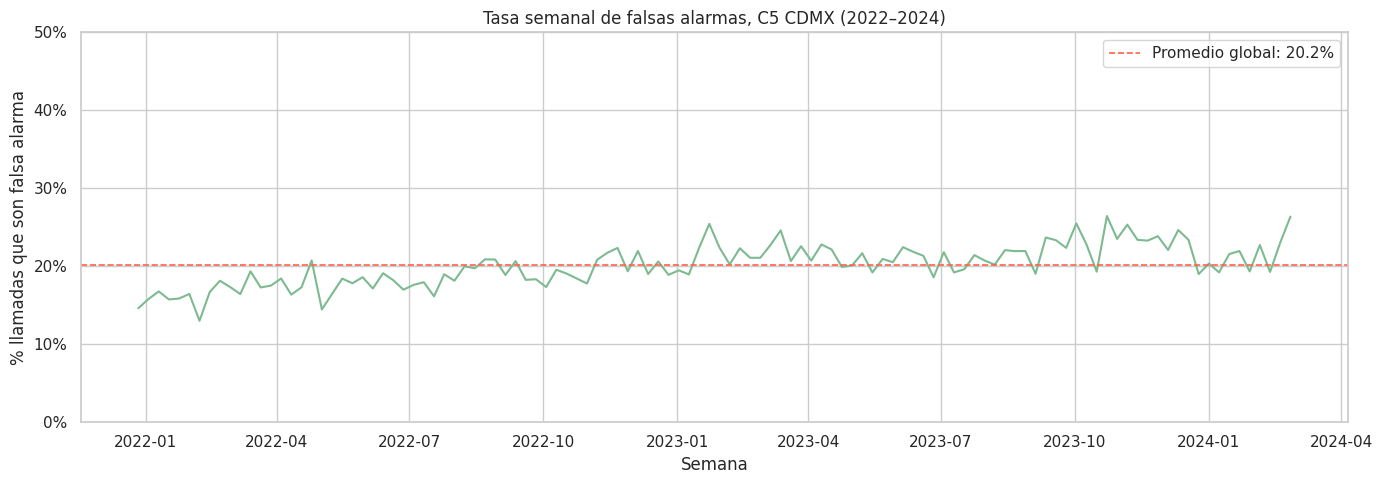

In [26]:
# Creamos la etiqueta para la gráfica (F=1, todo lo demás=0)
df['is_f_cierre'] = (df['codigo_cierre'] == 'F').astype(int)

# Agrupamos por semana y calculamos la tasa
df['semana'] = df['fecha_hora_creacion'].dt.to_period('W')
tasa_semanal = df.groupby('semana')['is_f_cierre'].mean().reset_index()
tasa_semanal['semana_dt'] = tasa_semanal['semana'].dt.to_timestamp()

# Gráfica
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(tasa_semanal['semana_dt'], tasa_semanal['is_f_cierre'], linewidth=1.5)
ax.axhline(df['is_f_cierre'].mean(), color='tomato', linestyle='--', linewidth=1.2, label=f'Promedio global: {df["is_f_cierre"].mean():.1%}')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_title('Tasa semanal de falsas alarmas, C5 CDMX (2022–2024)')
ax.set_xlabel('Semana')
ax.set_ylabel('% llamadas que son falsa alarma')
ax.legend()
ax.set_ylim(0, 0.5)
plt.tight_layout()

plt.show()

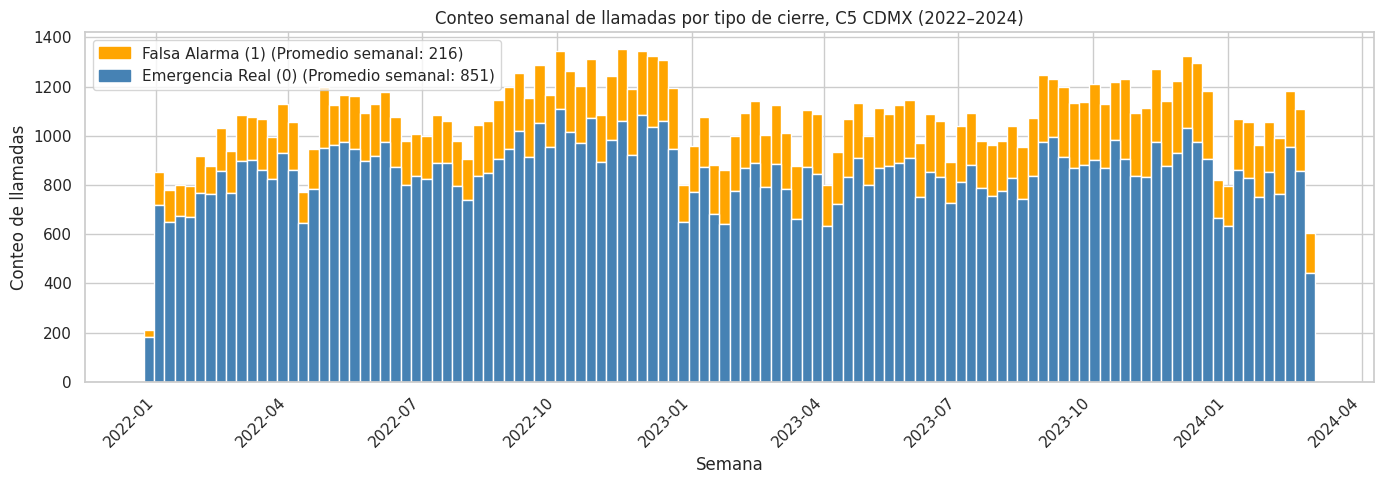

In [27]:
# Agrupamos por semana y el tipo de cierre (0 o 1) y contamos
weekly_counts = df.groupby(['semana', 'is_f_cierre']).size().unstack(fill_value=0)
weekly_counts = weekly_counts.reset_index()
weekly_counts['semana_dt'] = weekly_counts['semana'].dt.to_timestamp()

# Renombramos columnas para claridad en la gráfica
weekly_counts = weekly_counts.rename(columns={0: 'Emergencia Real (0)', 1: 'Falsa Alarma (1)'})

# Calculate weekly averages
avg_false_alarms = weekly_counts['Falsa Alarma (1)'].mean()
avg_real_emergencies = weekly_counts['Emergencia Real (0)'].mean()

# Gráfica de barras apiladas
fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(weekly_counts['semana_dt'], weekly_counts['Falsa Alarma (1)'], width=7, color='orange', bottom=weekly_counts['Emergencia Real (0)'], label='Falsa Alarma (1)')
ax.bar(weekly_counts['semana_dt'], weekly_counts['Emergencia Real (0)'], width=7, color='steelblue', label='Emergencia Real (0)')

ax.set_title('Conteo semanal de llamadas por tipo de cierre, C5 CDMX (2022–2024)')
ax.set_xlabel('Semana')
ax.set_ylabel('Conteo de llamadas') # Etiqueta del eje Y actualizada

# Create custom legend handles to include averages
legend_handles = [
    mpatches.Patch(color='orange', label=f'Falsa Alarma (1) (Promedio semanal: {avg_false_alarms:.0f})'),
    mpatches.Patch(color='steelblue', label=f'Emergencia Real (0) (Promedio semanal: {avg_real_emergencies:.0f})')
]
ax.legend(handles=legend_handles)

plt.xticks(rotation=45, ha='right') # Rotar etiquetas del eje X para mejor legibilidad
plt.tight_layout()
plt.show()

> **PREGUNTAS (observa los gráficos):**
> ¿La tasa de falsas alarmas es constante a lo largo del tiempo, o ves alguna tendencia o patrón? ¿Qué implicación tiene esto para un modelo de predicción? ¿Cuántas llamadas al día calculas que hay? ¿Cuántas que son falsas alarmas?

*Escribe tu respuesta aquí:*

### 2.2 Distribución por alcaldía y tipo de incidente

Información adicional sobre la tasa de falsas alarmas considerando las variables de predicción.

> **PREGUNTA:**
> ¿Coincide con tu análisis exploratorio?

*Escribe tu respuesta aquí:*

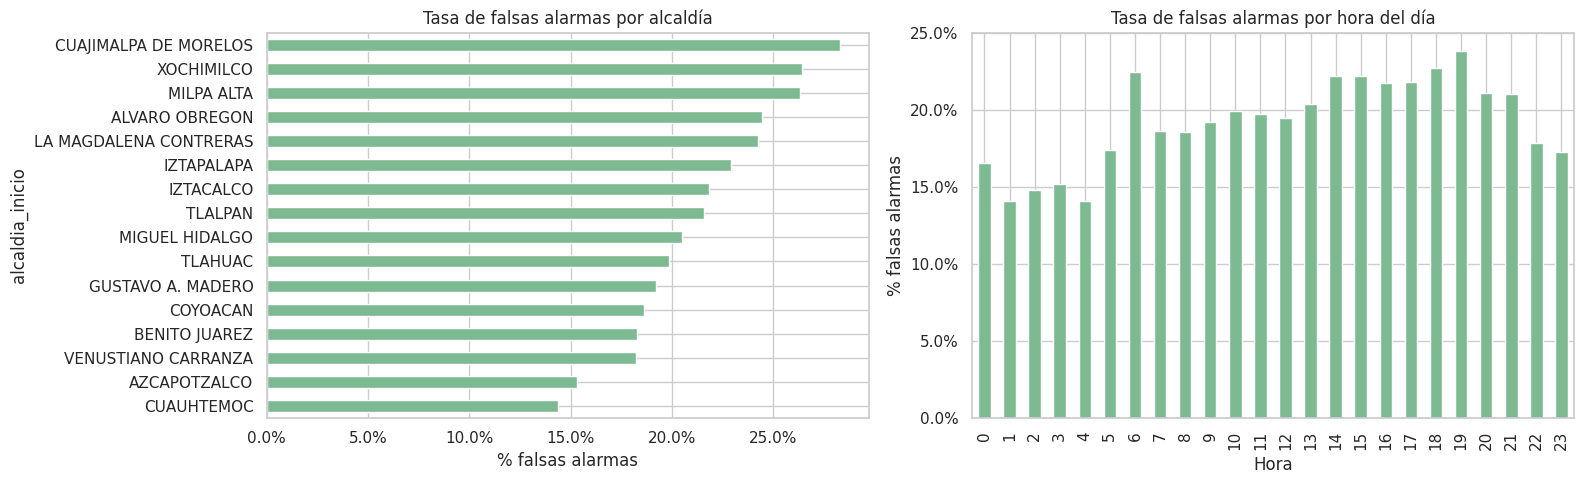

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Tasa de falsas alarmas por alcaldía
tasa_alcaldia = df.groupby('alcaldia_inicio')['is_f_cierre'].mean().sort_values(ascending=True)
tasa_alcaldia.plot(kind='barh', ax=axes[0])
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
axes[0].set_title('Tasa de falsas alarmas por alcaldía')
axes[0].set_xlabel('% falsas alarmas')

# Tasa de falsas alarmas por hora del día
tasa_hora = df.groupby(df['fecha_hora_creacion'].dt.hour)['is_f_cierre'].mean()
tasa_hora.plot(kind='bar', ax=axes[1])
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
axes[1].set_title('Tasa de falsas alarmas por hora del día')
axes[1].set_xlabel('Hora')
axes[1].set_ylabel('% falsas alarmas')

plt.tight_layout()
plt.show()

---
## 3. Creación de la etiqueta y los features

### 3.1 Etiqueta (variable que queremos predecir `y`)

- `1` = la llamada fue una falsa alarma (`codigo_cierre == 'F'`)
- `0` = la llamada fue una emergencia real (atendida, duplicada o informativa)

### 3.2 Features o predictores (variables que utiliza el modelo para aprender `X`)

Solo podemos usar información disponible *en el momento en que entra el reporte*, no podemos usar variables que se conocen hasta después de que ya se tomó la decisión.

| Feature | Tipo | Disponible al momento del reporte |
|---------|------|:-------------------------------:|
| `incidente_c4` | Categórica | Sí |
| `tipo_incidente_c4` | Categórica | Sí |
| `alcaldia_inicio` | Categórica | Sí |
| `tipo_entrada` | Categórica | Sí |
| `hora_del_dia` | Numérica | Sí |
| `dia_semana` | Numérica | Sí |

> **PREGUNTA:**
> ¿Por qué crees que no puedes tomar todas las variables de la base de datos como predictores?

*Escribe tu respuesta aquí:*


#### 3.2.1 One hot encoding

Los algoritmos de Machine Learning no pueden trabajar directamente con categorías o texto. Necesitamos convertir las variables categóricas (como `alcaldia_inicio`) a números.

One Hot Encoding crea una columna nueva por cada categoría posible, con valor `1` si el registro pertenece a esa categoría y `0` si no:

```text
alcaldia_inicio       →    alcaldia_IZTAPALAPA  alcaldia_COYOACAN  alcaldia_CUAUHTEMOC ...
IZTAPALAPA                       1                    0                   0
COYOACAN                         0                    1                   0
CUAUHTEMOC                       0                    0                   1
```

`pd.get_dummies()` hace esto automáticamente. Usamos `drop_first=True` para evitar redundancia matemática (si no es ninguna de las otras, es la primera).

Observa que la matriz resultante contiene valores `False` y `True`, esto se llama variable booleana. En Python, `False` equivale a `0` y `True` equivale a `1`, por lo que el modelo puede trabajar con estos valores directamente sin necesidad de convertirlos.

In [29]:
# Extraemos features de tiempo
df['hora_del_dia'] = df['fecha_hora_creacion'].dt.hour
df['dia_semana']   = df['fecha_hora_creacion'].dt.dayofweek  # 0=lunes, 6=domingo

# Seleccionamos las columnas del modelo
columnas_categoricas = ['incidente_c4', 'tipo_incidente_c4', 'alcaldia_inicio', 'tipo_entrada']
columnas_numericas   = ['hora_del_dia', 'dia_semana']

# One Hot Encoding para las variables categóricas
X_cat = pd.get_dummies(df[columnas_categoricas], drop_first=True)
X_num = df[columnas_numericas]

# Unimos todo en una sola matriz de features
X = pd.concat([X_cat, X_num], axis=1)

# Etiqueta
y = df['is_f_cierre']

print(f'Dimensiones de X: {X.shape}  → {X.shape[0]:,} llamadas, {X.shape[1]} features')
print(f'Tasa de falsas alarmas y: {y.mean():.1%}')
X.head(10)

Dimensiones de X: (121540, 44)  → 121,540 llamadas, 44 features
Tasa de falsas alarmas y: 20.2%


,incidente_c4_Atropellado,incidente_c4_Choque con lesionados,incidente_c4_Choque con prensados,incidente_c4_Choque sin lesionados,incidente_c4_Ciclista,incidente_c4_Ferroviario,incidente_c4_Incidente de tránsito,incidente_c4_Monopatín,incidente_c4_Motociclista,incidente_c4_Otros,...,alcaldia_inicio_VENUSTIANO CARRANZA,alcaldia_inicio_XOCHIMILCO,tipo_entrada_BOTÓN DE AUXILIO,tipo_entrada_CÁMARA,tipo_entrada_LLAMADA APP911,tipo_entrada_LLAMADA DEL 911,tipo_entrada_RADIO,tipo_entrada_REDES,hora_del_dia,dia_semana
0,False,False,False,True,False,False,False,False,False,False,...,True,False,False,False,False,True,False,False,18,4
1,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,2,0
2,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,4,6
3,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,16,3
4,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,19,3
5,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,20,5
6,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,9,5
7,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,8,2
8,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,19,0
9,False,False,False,True,False,False,False,False,False,False,...,True,False,False,False,False,True,False,False,10,0


> **PREGUNTA:**
> Observa las dimensiones de la matriz `X` que se imprimió arriba. ¿Cuántas variables (columnas) quedaron después de aplicar One Hot Encoding?

*Escribe tu respuesta aquí*

### 3.3 Ingeniería de variables

Hasta ahora el modelo usa las variables tal como vienen en la base. La **ingeniería de variables** consiste en crear columnas nuevas a partir de las que ya tenemos, para darle al modelo información que no vería directamente.

| Variable | Qué captura | Cómo se calcula |
|----------|-------------|-----------------|
| `hora_sin`, `hora_cos` | Hora en forma cíclica: la hora 23 queda cerca de la hora 0 | Seno y coseno de la hora |
| `fin_de_semana` | Si el reporte es sábado o domingo | `dia_semana >= 5` |
| `franja_horaria` | Momento del día en grandes bloques | Madrugada, mañana, tarde y noche |
| `mes` | Estacionalidad a lo largo del año | Mes de la fecha de creación |
| `es_festivo` | Días de asueto, que cambian el tránsito y las llamadas | Fecha contra la lista de festivos oficiales |
| `tasa_f_colonia` | Qué tan frecuentes han sido las falsas alarmas en la colonia | Falsas alarmas previas / llamadas previas de la colonia |
| `llamadas_colonia_1h` | Actividad reciente en la colonia | Llamadas de la misma colonia en la hora anterior |
| `min_desde_ultima_colonia` | Qué tan seguido se reporta en la colonia | Minutos desde la llamada anterior de la misma colonia |

> **Importante:** las variables de historial (`tasa_f_colonia`, `llamadas_colonia_1h` y `min_desde_ultima_colonia`) solo usan llamadas que ocurrieron **antes** del reporte. Si usáramos llamadas posteriores, el modelo estaría viendo el futuro.

In [ ]:
## ── Variables de tiempo ──────────────────────────────────────────────────
## Hora en forma cíclica: la hora 23 queda cerca de la hora 0
#df['hora_sin'] = np.sin(2 * np.pi * df['hora_del_dia'] / 24)
#df['hora_cos'] = np.cos(2 * np.pi * df['hora_del_dia'] / 24)
#
## Fin de semana (dia_semana: 5 = sábado, 6 = domingo)
#df['fin_de_semana'] = (df['dia_semana'] >= 5).astype(int)
#
## Mes de la llamada
#df['mes'] = df['fecha_hora_creacion'].dt.month
#
## Franja horaria
#df['franja_horaria'] = pd.cut(
#    df['hora_del_dia'],
#    bins=[-1, 5, 11, 17, 23],
#    labels=['madrugada', 'mañana', 'tarde', 'noche']
#)
#
## Días festivos oficiales en México (2022–2024)
#festivos = pd.to_datetime([
#    '2022-01-01', '2022-02-07', '2022-03-21', '2022-05-01', '2022-09-16', '2022-11-21', '2022-12-25',
#    '2023-01-01', '2023-02-06', '2023-03-20', '2023-05-01', '2023-09-16', '2023-11-20', '2023-12-25',
#    '2024-01-01', '2024-02-05', '2024-03-18', '2024-05-01', '2024-09-16', '2024-10-01', '2024-11-18', '2024-12-25',
#])
#df['es_festivo'] = df['fecha_hora_creacion'].dt.normalize().isin(festivos).astype(int)
#
## ── Variables de historial por colonia ───────────────────────────────────
## Tasa histórica de falsas alarmas: solo contamos llamadas anteriores al reporte
#df_ord = df.sort_values('fecha_hora_creacion')
#grupo_colonia = df_ord.groupby('colonia_catalogo')['is_f_cierre']
#
#falsas_previas   = grupo_colonia.cumsum() - df_ord['is_f_cierre']  # restamos la llamada actual
#llamadas_previas = grupo_colonia.cumcount()
#tasa_previa = (falsas_previas / llamadas_previas).reindex(df.index)
#
## Si la colonia no tiene historial, usamos la tasa global
#df['tasa_f_colonia'] = tasa_previa.fillna(df['is_f_cierre'].mean())
#
## Llamadas de la misma colonia en la última hora (sin contar la llamada actual)
#df['llamadas_colonia_1h'] = (
#    df.groupby('colonia_catalogo')['fecha_hora_creacion']
#      .transform(lambda t: t.apply(lambda x: ((t < x) & (t >= x - pd.Timedelta('1h'))).sum()))
#)
#
## Minutos desde la llamada anterior de la misma colonia
#df_col = df.sort_values(['colonia_catalogo', 'fecha_hora_creacion'])
#minutos = df_col.groupby('colonia_catalogo')['fecha_hora_creacion'].diff().dt.total_seconds() / 60
#df['min_desde_ultima_colonia'] = minutos.reindex(df.index)
#
## Primera llamada de cada colonia: no hay llamada anterior, le damos el valor máximo
#df['min_desde_ultima_colonia'] = df['min_desde_ultima_colonia'].fillna(df['min_desde_ultima_colonia'].max())
#
## ── Agregamos las nuevas variables a X ───────────────────────────────────
#columnas_nuevas = ['hora_sin', 'hora_cos', 'fin_de_semana', 'mes', 'es_festivo',
#                   'tasa_f_colonia', 'llamadas_colonia_1h', 'min_desde_ultima_colonia']
#
#X_franja = pd.get_dummies(df['franja_horaria'], prefix='franja', drop_first=True)
#X = pd.concat([X, df[columnas_nuevas], X_franja], axis=1)
#
#print(f'Dimensiones de X con ingeniería de variables: {X.shape}')
#df[columnas_nuevas].describe().T[['mean', 'min', 'max']]

> **PREGUNTA:**
> Revisa la tabla de estadísticas de arriba. ¿Qué variable nueva tiene el rango más amplio? ¿Por qué crees que `min_desde_ultima_colonia` necesita un tratamiento especial para la primera llamada de cada colonia?

*Escribe tu respuesta aquí:*


---
## 4. Cross Validation o Validación cruzada aleatoria

- Dividimos los datos en 80% para entrenar y 20% para evaluar.
- En esta primera versión usamos una división **aleatoria**.

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Datos de entrenamiento: {len(X_train):,} llamadas')
print(f'Datos de prueba:        {len(X_test):,} llamadas')

Datos de entrenamiento: 97,232 llamadas
Datos de prueba:        24,308 llamadas



> **PREGUNTA:**
> En el split aleatorio, una llamada del 15 de marzo de 2023 puede quedar en entrenamiento y otra del 14 de marzo de 2023 puede quedar en prueba. ¿Qué problema representa esto para evaluar un modelo que usado en la vida real siempre predice sobre llamadas *futuras*? ¿Por qué esto es especialmente relevante cuando los datos tienen un orden temporal?

*Escribe tu respuesta aquí:*

---
## 5. Modelos

Entrenamos cuatro modelos para poder compararlos. Empezamos con una **línea base** (Dummy Classifier) que nos dice qué tan bien lo haría un modelo que no aprende nada.

| Modelo | ¿Qué hace? |
|--------|------------|
| **Dummy Classifier** | Predice siempre la clase más frecuente (línea base) |
| **Árbol de Decisión** | Aprende reglas tipo "si X entonces Y" |
| **Regresión Logística** | Aprende una combinación lineal de los features |
| **Random Forest** | Combina muchos árboles para una predicción más robusta |


> **PREGUNTA:** ¿Qué otra línea base puedes considerar a partir de los datos disponibles?

*Escribe tu respuesta aquí:*

In [32]:
# Escalamos las variables numéricas para la Regresión Logística
# (no afecta a árboles, pero sí a modelos lineales)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Definimos los modelos
modelos = {
    'Línea base (Dummy)':    DummyClassifier(strategy='most_frequent', random_state=42),
    'Árbol de Decisión':     DecisionTreeClassifier(max_depth=5, random_state=42),
    'Regresión Logística':   LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':         RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
}

# Entrenamos todos
resultados = {}
for nombre, modelo in modelos.items():
    if nombre == 'Regresión Logística':
        modelo.fit(X_train_scaled, y_train)
        scores = modelo.predict_proba(X_test_scaled)[:, 1]
    else:
        modelo.fit(X_train, y_train)
        scores = modelo.predict_proba(X_test)[:, 1]

    resultados[nombre] = pd.DataFrame({
        'id_llamada':         df.loc[X_test.index, 'folio'].values,
        'etiqueta_real':      y_test.values,
        'score_falsa_alarma': scores
    })
    print(f'✓ {nombre} entrenado')

✓ Línea base (Dummy) entrenado
✓ Árbol de Decisión entrenado
✓ Regresión Logística entrenado
✓ Random Forest entrenado


### 5.1 Evaluación de scores

La gráfica muestra la distribución de scores separada por lo que realmente ocurrió (etiqueta real). En un modelo ideal veríamos dos grupos bien separados: las falsas alarmas reales acumuladas cerca de 1 y las emergencias reales acumuladas cerca de 0. Entre más se traslapen las dos distribuciones, más le cuesta al modelo distinguir entre ambas.

> **COMPLEMENTA:**
> ¿Qué significa el score? ¿Qué observas en estos gráficos?

*Escribe tu respuesta aquí:*


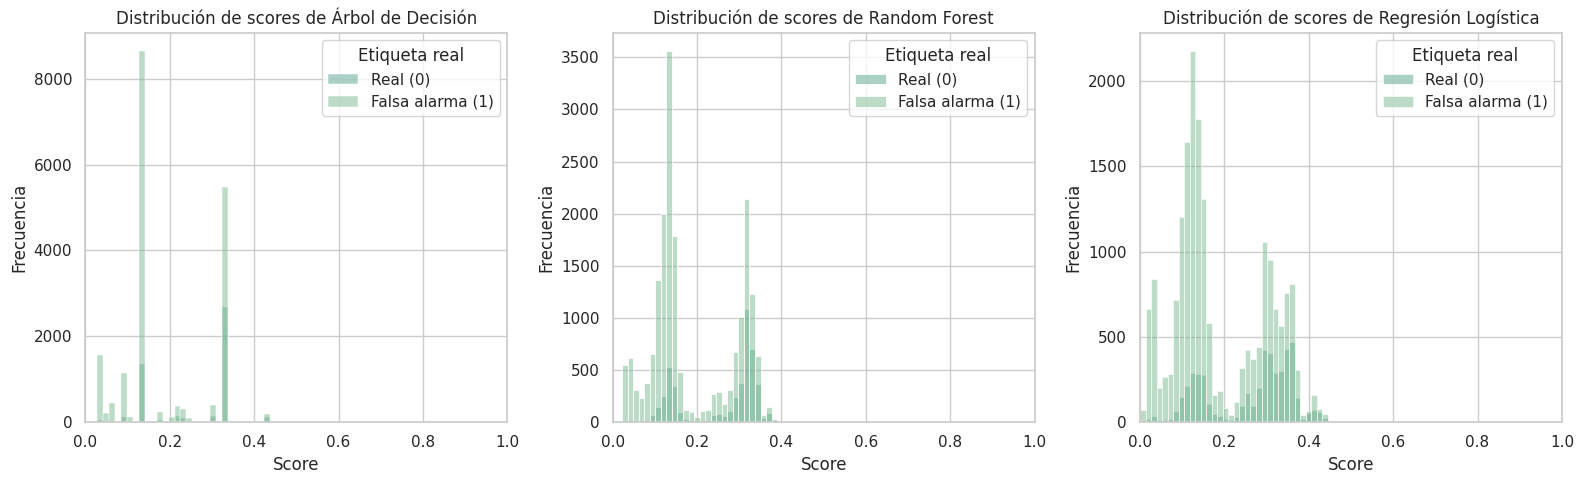

In [33]:
# Distribución de scores
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, nombre in zip(axes, ['Árbol de Decisión', 'Random Forest', 'Regresión Logística']):
    sns.histplot(
        data=resultados[nombre],
        x='score_falsa_alarma',
        hue='etiqueta_real',
        ax=ax
    )
    ax.set_title(f'Distribución de scores de {nombre}')
    ax.set_xlabel('Score')
    ax.set_ylabel('Frecuencia')
    ax.set_xlim(0, 1)
    ax.legend(title='Etiqueta real', labels=['Real (0)', 'Falsa alarma (1)'])

plt.tight_layout()
plt.show()

## 6. Métricas globales sobre score mayor a 0.5

Recuerda que para cada llamada en el conjunto de prueba tenemos dos cosas:

- la **etiqueta real** (lo que realmente ocurrió)
- y el **score** que el modelo le asignó.
  - Con un umbral de 0.5, el modelo predice `1` (falsa alarma) para todas las llamadas con score mayor a 0.5,
  - y `0` (emergencia real) para las demás.

Es con base en esta clasificación que calculamos los verdaderos positivos, falsos positivos,
verdaderos negativos y falsos negativos de la tabla de arriba.

In [34]:
# Ejemplo de resultados con score de un algoritmo
resultados['Árbol de Decisión'].head(10)

,id_llamada,etiqueta_real,score_falsa_alarma
0,C5/20230702/06128,0,0.335137
1,C5/20240102/01991,0,0.035034
2,C2P/20231216/00065,0,0.042383
3,C5/20221202/05384,0,0.130226
4,C5/20220516/02703,0,0.130226
5,C5/20220620/01243,0,0.335137
6,C5/20230421/04706,0,0.130226
7,C5/20220428/02847,0,0.130226
8,C5/20231219/03299,0,0.335137
9,C5/20221127/04199,1,0.335137


In [35]:
# Métricas con umbral score > 0.5
print(f"{'Modelo':<25} {'Total+reales':>13} {'TP':>8} {'FP':>8} {'TN':>8} {'FN':>8} {'Accuracy':>10} {'Eficiencia':>12} {'Cobertura':>11}")
print('-' * 110)

for nombre, df_res in resultados.items():
    alta_confianza  = df_res[df_res['score_falsa_alarma'] > 0.5]
    baja_confianza  = df_res[df_res['score_falsa_alarma'] <= 0.5]
    total_positivos = (df_res['etiqueta_real'] == 1).sum()
    tp              = (alta_confianza['etiqueta_real'] == 1).sum()
    fp              = (alta_confianza['etiqueta_real'] == 0).sum()
    tn              = (baja_confianza['etiqueta_real'] == 0).sum()
    fn              = (baja_confianza['etiqueta_real'] == 1).sum()
    accuracy        = (tp + tn) / len(df_res)
    eficiencia      = tp / len(alta_confianza) if len(alta_confianza) > 0 else 0
    cobertura       = tp / total_positivos

    print(f"{nombre:<25} {total_positivos:>13,} {tp:>8,} {fp:>8,} {tn:>8,} {fn:>8,} {accuracy:>10.1%} {eficiencia:>12.1%} {cobertura:>11.1%}")

Modelo                     Total+reales       TP       FP       TN       FN   Accuracy   Eficiencia   Cobertura
--------------------------------------------------------------------------------------------------------------
Línea base (Dummy)                4,913        0        0   19,395    4,913      79.8%         0.0%        0.0%
Árbol de Decisión                 4,913        6        7   19,388    4,907      79.8%        46.2%        0.1%
Regresión Logística               4,913        3        6   19,389    4,910      79.8%        33.3%        0.1%
Random Forest                     4,913        4        1   19,394    4,909      79.8%        80.0%        0.1%


> **PREGUNTA:** ¿Qué observas en las métricas? ¿Cuál es el mejor modelo en eficiencia y con qué valor? ¿Qué hay de la cobertura?

*Escribe tu respuesta aquí*

### 6.1 Curva ROC

La tabla anterior depende de un solo umbral (0.5). La **curva ROC** muestra qué pasa con todos los umbrales posibles, al graficar en cada uno:

- **TPR (sensibilidad)** = $\frac{TP}{TP + FN}$: fracción de las falsas alarmas que el modelo detecta.
- **FPR** = $\frac{FP}{FP + TN}$: fracción de las emergencias reales que el modelo marcaría como falsa alarma (y que, por lo tanto, podrían retrasar un despacho).

Un modelo que no aprende nada sigue la diagonal. Entre más se acerque la curva a la esquina superior izquierda, mejor separa las dos clases.

El **AUC** (área bajo la curva) resume la curva en un número: es la probabilidad de que el modelo asigne un score más alto a una falsa alarma tomada al azar que a una emergencia real tomada al azar. Azar = 0.5, perfecto = 1.0.

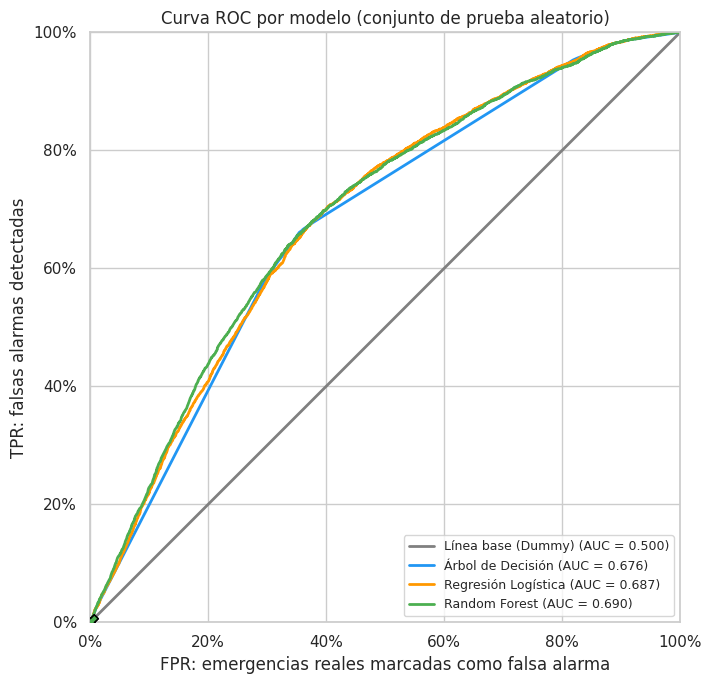

In [36]:
colores_modelos = {
    'Línea base (Dummy)':  'gray',
    'Árbol de Decisión':   '#2196F3',
    'Regresión Logística': '#FF9800',
    'Random Forest':       '#4CAF50',
}

fig, ax = plt.subplots(figsize=(8, 7))

for nombre, color in colores_modelos.items():
    df_res = resultados[nombre]
    etiqueta = df_res['etiqueta_real']
    score    = df_res['score_falsa_alarma']

    fpr, tpr, _ = roc_curve(etiqueta, score)
    auc = roc_auc_score(etiqueta, score)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f'{nombre} (AUC = {auc:.3f})')

    # Punto correspondiente al umbral 0.5 usado en la tabla de la sección 6
    pred_05 = score > 0.5
    tpr_05  = (pred_05 & (etiqueta == 1)).sum() / (etiqueta == 1).sum()
    fpr_05  = (pred_05 & (etiqueta == 0)).sum() / (etiqueta == 0).sum()
    ax.scatter(fpr_05, tpr_05, color=color, s=120, marker='X', edgecolor='black', zorder=5)

#ax.scatter([], [], color='white', edgecolor='black', s=120, marker='X', label='Umbral 0.5 (sección 6)')
#ax.plot([0, 1], [0, 1], color='black', linestyle=':', linewidth=1, label='Azar (AUC = 0.5)')

ax.set_title('Curva ROC por modelo (conjunto de prueba aleatorio)')
ax.set_xlabel('FPR: emergencias reales marcadas como falsa alarma')
ax.set_ylabel('TPR: falsas alarmas detectadas')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect('equal')
ax.legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()

> **PREGUNTAS:**
> 1. ¿Qué modelo tiene la curva más cercana a la esquina superior izquierda? ¿Qué significaría llegar a esa esquina?
> 2. Observa las $X$ (umbral 0.5). ¿Dónde caen en la curva? ¿Coinciden con lo que viste en la tabla de métricas?
> 3. Supón que el C5 no tolera que más de 5% de las emergencias reales se marquen como falsa alarma (FPR $\leq$ 5%). ¿Qué TPR alcanza cada modelo bajo esa restricción? ¿Cuál elegirías?
> 4. El AUC no depende del umbral, pero el C5 opera con un $k$ fijo (sección 8). ¿Qué ventaja y qué limitación tiene el AUC para este problema?

*Escribe tu respuesta aquí:*

---
---
---

## 7. Validación temporal cruzada

En la sección anterior dividimos los datos de forma **aleatoria**. Pero los modelos en producción siempre predicen sobre el futuro usando datos del pasado, no tienen acceso a datos futuros durante el entrenamiento.

Cuando hacemos split aleatorio, el modelo puede "ver el futuro" accidentalmente: aprende de llamadas de diciembre 2023 y se evalúa en llamadas de enero 2022. Eso infla artificialmente el desempeño.

La **validación temporal** respeta el orden cronológico: siempre entrenamos con datos anteriores y evaluamos con datos posteriores.

```text
Split 1: |--- Train 1 -----|--- Test 1 ---|
Split 2: |--- Train 2 -----------------|--- Test 2 ---|
Split 3: |--- Train 3 -----------------------------|--- Test 3 ---|
Split 3: |--- Train 4 -----------------------------------------|--- Test 4 ---|
```

In [ ]:
# Ordenamos por fecha y agregamos columna de año-mes para los cortes
df_sorted = df.sort_values('fecha_hora_creacion').copy()

# Definimos los 3 splits temporales
splits_temporales = [
    {'nombre': 'Split 1 (test: 1er tri 2023)',
     'train_hasta': '2022-12-31',
     'test_desde':  '2023-01-01',
     'test_hasta':  '2023-03-31'},
    {'nombre': 'Split 2 (test: 2do tri 2023)',
     'train_hasta': '2023-03-31',
     'test_desde':  '2023-04-01',
     'test_hasta':  '2023-06-30'},
    {'nombre': 'Split 3 (test: 3er tri 2023)',
     'train_hasta': '2023-06-30',
     'test_desde':  '2023-07-01',
     'test_hasta':  '2023-09-30'},
    {'nombre': 'Split 4 (test: 4t0 tri 2023)',
     'train_hasta': '2023-09-30',
     'test_desde':  '2023-10-01',
     'test_hasta':  '2023-12-31'},
]

print('Tamaños de cada split:')
for s in splits_temporales:
    train = df_sorted[df_sorted['fecha_hora_creacion'] <= s['train_hasta']]
    test  = df_sorted[(df_sorted['fecha_hora_creacion'] >= s['test_desde']) &
                      (df_sorted['fecha_hora_creacion'] <= s['test_hasta'])]
    print(f"  {s['nombre']}: train={len(train):,}, test={len(test):,}")

In [ ]:
def eficiencia_cobertura_k(df_resultados, k):
    """Calcula eficiencia@k y cobertura@k dado un DataFrame con scores."""
    top_k           = df_resultados.nlargest(k, 'score_falsa_alarma')
    tp              = (top_k['etiqueta_real'] == 1).sum()
    total_positivos = (df_resultados['etiqueta_real'] == 1).sum()
    return tp / k, tp / total_positivos

############################# REVISA ##########################
# ── Definición de k operativo ────────────────────────────────────────────
# Cada split de prueba cubre un trimestre (~90 días).
# SUPUESTO operativo: en cada turno de 8 horas un operador puede activar
# cámaras para verificar 5 llamadas sospechosas.
# Con 3 turnos al día durante 90 días → k = 5 × 3 × 90 = 1,350
verificaciones_por_turno = 5     ### <------------
turnos_por_dia           = 3
dias_trimestre           = 90
k_temporal = verificaciones_por_turno * turnos_por_dia * dias_trimestre
print(f'k operativo para un trimestre: {k_temporal:,} verificaciones')


# ── Modelos ──────────────────────────────────────────────────────────────
modelos_temporales = {
    'Línea base (Dummy)':  DummyClassifier(strategy='most_frequent', random_state=42),
    'Árbol de Decisión':   DecisionTreeClassifier(max_depth=5, random_state=42),
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
}

resultados_temporales = []
resultados_split4     = {}   # guardamos scores del Split 4 para la curva de la sección 8

for s in splits_temporales:
    mask_train = df_sorted['fecha_hora_creacion'] <= s['train_hasta']
    mask_test  = ((df_sorted['fecha_hora_creacion'] >= s['test_desde']) &
                  (df_sorted['fecha_hora_creacion'] <= s['test_hasta']))

    X_tr = X.loc[df_sorted[mask_train].index]
    y_tr = y.loc[df_sorted[mask_train].index]
    X_te = X.loc[df_sorted[mask_test].index]
    y_te = y.loc[df_sorted[mask_test].index]

    scaler_t    = StandardScaler()
    X_tr_scaled = scaler_t.fit_transform(X_tr)
    X_te_scaled = scaler_t.transform(X_te)

    for nombre, modelo in modelos_temporales.items():
        if nombre == 'Regresión Logística':
            modelo.fit(X_tr_scaled, y_tr)
            scores_te = modelo.predict_proba(X_te_scaled)[:, 1]
        else:
            modelo.fit(X_tr, y_tr)
            scores_te = modelo.predict_proba(X_te)[:, 1]

        df_res = pd.DataFrame({'etiqueta_real': y_te.values, 'score_falsa_alarma': scores_te})
        ef, cob = eficiencia_cobertura_k(df_res, k_temporal)

        resultados_temporales.append({
            'split':      s['nombre'],
            'modelo':     nombre,
            'eficiencia@k': ef,
            'cobertura@k':  cob,
        })

        # Guardamos resultados del Split 4 para la curva de eficiencia/cobertura
        if s['nombre'].startswith('Split 4'):
            resultados_split4[nombre] = df_res

    print(f"✓ {s['nombre']} completado")

df_temp = pd.DataFrame(resultados_temporales)



---
## 8. Métricas de Eficiencia y Cobertura @k

En este problema no nos basta con la precisión global del modelo. Lo que importa es cómo se desempeña cuando el C5 tiene que decidir *con recursos limitados*.

> **PREGUNTA:** El C5 recibe cientos de llamadas al día pero cuenta con un número finito de operadores y cámaras disponibles para hacer verificaciones. ¿Qué implica esto para la forma en que el modelo debe priorizar las llamadas? ¿Qué pasaría si intentáramos verificar *todas* las llamadas con score mayor a 0.5?

*Escribe tu respuesta aquí*


### Contexto operativo

Cada vez que entra una llamada al C5, el modelo le asigna un score y las ordena de mayor a menor riesgo de ser falsa alarma. El operador toma las $k$ llamadas con score más alto y activa las cámaras para verificarlas antes de despachar una unidad. Solo puede revisar $k$ llamadas, no todas, porque el tiempo y las cámaras disponibles son limitados.

Con eso en mente, definimos dos métricas que nos dicen qué tan bien está usando el modelo esos $k$ espacios de verificación:

$$\text{Eficiencia@k} = \frac{\text{verdaderos positivos en el top-}k}{k}$$

De las $k$ llamadas que el modelo seleccionó para verificar, ¿qué fracción realmente eran falsas alarmas? Si la eficiencia es baja, estamos verificando llamadas de emergencias reales que deberíamos haber despachado de inmediato.

$$\text{Cobertura@k} = \frac{\text{verdaderos positivos en el top-}k}{\text{total de falsas alarmas}}$$

De todas las falsas alarmas que entraron en ese periodo, ¿qué fracción logramos detectar? Si la cobertura es baja, muchas falsas alarmas están pasando como emergencias reales y estamos despachando unidades innecesariamente.

In [ ]:
print(df_temp.to_string(index=False))

In [ ]:
df_temp

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

labels_cortos = ['Split 1\n1er tri 2023', 'Split 2\n2do tri 2023', 'Split 3\n3er tri 2023', 'Split 4\n4to tri 2023']
colores_modelos = {
    'Línea base (Dummy)':  'gray',
    'Árbol de Decisión':   '#2196F3',
    'Regresión Logística': '#FF9800',
    'Random Forest':       '#4CAF50',
}
x = np.arange(len(labels_cortos))

for nombre, color in colores_modelos.items():
    eficiencias = df_temp[df_temp['modelo'] == nombre]['eficiencia@k'].values
    coberturas  = df_temp[df_temp['modelo'] == nombre]['cobertura@k'].values
    axes[0].plot(x, eficiencias, marker='o', label=nombre, color=color, linewidth=2)
    axes[1].plot(x, coberturas,  marker='o', label=nombre, color=color, linewidth=2)

for ax, titulo, metrica in zip(axes,
    [f'Eficiencia@{k_temporal} por modelo y split temporal',
     f'Cobertura@{k_temporal} por modelo y split temporal'],
    ['Eficiencia@k', 'Cobertura@k']):
    ax.set_xticks(x)
    ax.set_xticklabels(labels_cortos)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
    ax.set_title(titulo)
    ax.set_ylabel(metrica)
    ax.set_ylim(0, 1)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

> **PREGUNTAS:**
> 1. ¿Las métricas son estables entre splits o cambian a lo largo del tiempo? ¿Qué te dice eso sobre el modelo?
> 2. Compara la eficiencia y cobertura del Split 4 con las métricas obtenidas con el split aleatorio (sección 6). ¿Hay diferencia? ¿Cuál evaluación es más confiable para una decisión de política pública?


*Escribe tu respuesta aquí:*

In [ ]:
# Curva de eficiencia y cobertura para distintos valores de k
# Usamos los resultados del Split 4 (4to trimestre 2023 — el más cercano a producción)
n_test_split4 = len(next(iter(resultados_split4.values())))
ks = list(range(100, n_test_split4, 100))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

colores_modelos = {
    'Línea base (Dummy)':  'gray',
    'Árbol de Decisión':   '#2196F3',
    'Regresión Logística': '#FF9800',
    'Random Forest':       '#4CAF50',
}

for nombre, color in colores_modelos.items():
    df_res      = resultados_split4[nombre]
    eficiencias = [eficiencia_cobertura_k(df_res, k)[0] for k in ks]
    coberturas  = [eficiencia_cobertura_k(df_res, k)[1] for k in ks]
    axes[0].plot(ks, eficiencias, label=nombre, color=color, linewidth=2)
    axes[1].plot(ks, coberturas,  label=nombre, color=color, linewidth=2)

# Línea vertical en el k operativo
for ax in axes:
    ax.axvline(k_temporal, color='tomato', linestyle='--', linewidth=1.5,
               label=f'k operativo ({k_temporal:,})')

axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[0].set_title('Eficiencia@k por modelo — Split 4 (4to trimestre 2023)')
axes[0].set_xlabel('k (verificaciones)')
axes[0].set_ylabel('Eficiencia@k')
axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=9)

axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[1].set_title('Cobertura@k por modelo — Split 4 (4to trimestre 2023)')
axes[1].set_xlabel('k (verificaciones)')
axes[1].set_ylabel('Cobertura@k')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


Estas métricas están en tensión: aumentar $k$ mejora la cobertura pero reduce la eficiencia. Las curvas construidas con los resultados del **Split 4** muestran este intercambio para cada modelo. La línea vertical punteada marca el **k operativo** definido en la sección anterior ($k = 1{,}350$ verificaciones por trimestre).

> **PREGUNTA:**
> 1. ¿Qué le pasa a la eficiencia conforme aumentas $k$? Cuando $k$ es muy grande y se acerca al total de llamadas del conjunto de prueba, ¿hacia qué valor crees que converge la eficiencia? ¿Reconoces ese número en algún otro resultado que ya viste en el notebook?
> 2. ¿Existe algún valor de $k$ donde el Random Forest supera claramente al Árbol de Decisión en eficiencia o cobertura?
> 3. Si fueras directora o director de operaciones del C5, ¿con qué $k$ y qué modelo trabajarías? Justifica tu elección con los valores que observas en las curvas.

*Escribe tu respuesta aquí:*